# NB-P04-01 — Data Preparation

Companion notebook for P04 lessons 01–04. One deliberately messy dataset, worked through in the order a
real analysis uses: inspect, reshape, clean, treat outliers, scale, explore.

The dataset is generated with a fixed seed, so every count you see can be reproduced.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=21)
pd.set_option("display.width", 100)

## 1. Build the messy frame

Sixty survey responses, then six deliberate faults, each of which you will find by inspection rather
than by remembering this cell.

In [2]:
n = 60
raw = pd.DataFrame({
    "respondent_id": np.arange(1, n + 1),
    "name": [f"student {i:02d}" for i in range(1, n + 1)],
    "city": rng.choice(["Lahore", "Karachi", "Islamabad"], size=n),
    "satisfaction": rng.integers(1, 6, size=n).astype(float),
    "age": rng.integers(18, 30, size=n),
})

raw.loc[[2, 7, 11], "city"] = ["lahore ", "KARACHI", "Islamabad  "]
raw.loc[4, "name"] = "student 05  "
raw = pd.concat([raw, raw.iloc[[10]]], ignore_index=True)
raw.loc[[5, 19, 33, 47], "satisfaction"] = np.nan
raw.loc[12, "age"] = 213

print(raw.shape)
raw.head(8)

(61, 5)


,respondent_id,name,city,satisfaction,age
0,1,student 01,Lahore,1.0,21
1,2,student 02,Islamabad,4.0,22
2,3,student 03,lahore,1.0,26
3,4,student 04,Karachi,1.0,28
4,5,student 05,Karachi,2.0,26
5,6,student 06,Islamabad,NaN,24
6,7,student 07,Karachi,2.0,20
7,8,student 08,KARACHI,3.0,25


## 2. Inspect before changing anything

Four questions: how big, which columns are numeric, what is missing, and what looks impossible.

In [3]:
print("shape:", raw.shape)
print("numeric columns:", raw.select_dtypes("number").columns.tolist())
print("\nmissing per column:\n", raw.isna().sum().to_string())
print("\nrows where age > 100:\n", raw.loc[raw["age"] > 100].to_string(index=False))
print("\ncity spellings:", sorted(raw["city"].unique()))
print("duplicated rows:", int(raw.duplicated().sum()))

shape: (61, 5)
numeric columns: ['respondent_id', 'satisfaction', 'age']

missing per column:
 respondent_id    0
name             0
city             0
satisfaction     4
age              0

rows where age > 100:
  respondent_id       name   city  satisfaction  age
            13 student 13 Lahore           5.0  213

city spellings: ['Islamabad', 'Islamabad  ', 'KARACHI', 'Karachi', 'Lahore', 'lahore ']
duplicated rows: 1


## 3. Clean, recording every decision

Order matters: normalise categories, then deduplicate, then impute. Each step returns a count for the
report.

In [4]:
def clean(df):
    """Return (cleaned frame, report of what changed)."""
    report = {}
    out = df.copy()

    out["city"] = out["city"].str.strip().str.title()
    out["name"] = out["name"].str.strip()
    report["city values after normalising"] = sorted(out["city"].dropna().unique())

    before = len(out)
    out = out.drop_duplicates(subset=["respondent_id"], keep="first")
    report["duplicate ids removed"] = before - len(out)

    out["score_missing"] = out["satisfaction"].isna()
    report["scores imputed"] = int(out["score_missing"].sum())
    out["satisfaction"] = out["satisfaction"].fillna(out["satisfaction"].median())

    report["implausible ages"] = int((out["age"] > 100).sum())
    out.loc[out["age"] > 100, "age"] = np.nan
    out["age"] = out["age"].fillna(out["age"].median())

    report["remaining missing"] = int(out.isna().sum().sum())
    return out, report


clean_df, report = clean(raw)
for key, value in report.items():
    print(f"{key:32s} {value}")

print("\nshape after cleaning:", clean_df.shape)
print("median satisfaction:", clean_df["satisfaction"].median())

city values after normalising    ['Islamabad', 'Karachi', 'Lahore']
duplicate ids removed            1
scores imputed                   4
implausible ages                 1
remaining missing                0

shape after cleaning: (60, 6)
median satisfaction: 3.0


## 4. Duplicates need a key, not a guess

Ten rows can be identical in every column and still be legitimate; what makes a duplicate is sharing the
key that identifies a record. Inspect before dropping.

In [5]:
key_dupes = clean_df[clean_df.duplicated(subset=["name"], keep=False)].sort_values("name")
print(key_dupes.to_string(index=False))
print("\nrows sharing a name:", int(clean_df.duplicated(subset=["name"]).sum()))

Empty DataFrame
Columns: [respondent_id, name, city, satisfaction, age, score_missing]
Index: []

rows sharing a name: 0


## 5. Outliers: three rules, three answers

On the age column with the injected 213, compare the IQR fence, the z-score and the modified z-score.

In [6]:
ages = raw["age"].astype(float)
q1, q3 = ages.quantile([0.25, 0.75])
iqr = q3 - q1
fence = q3 + 1.5 * iqr

z = (ages - ages.mean()) / ages.std(ddof=1)
mad = (ages - ages.median()).abs().median()
modified_z = 0.6745 * (ages - ages.median()) / mad

summary = pd.DataFrame({
    "value": ages,
    "z": z.round(2),
    "modified_z": modified_z.round(2),
}).loc[lambda d: (d["value"] > fence) | (d["z"].abs() > 3) | (d["modified_z"].abs() > 3.5)]
print("upper fence:", round(fence, 2))
print("mean, sd  :", round(ages.mean(), 2), round(ages.std(ddof=1), 2))
summary

upper fence: 36.0
mean, sd  : 26.85 24.41


,value,z,modified_z
12,213.0,7.63,42.49


The z-score of the 213 row is modest because the outlier inflated the standard deviation — masking.
The IQR fence and the modified z-score flag it immediately.

In [7]:
print("flagged by fence      :", int((ages > fence).sum()))
print("flagged by |z| > 3    :", int((z.abs() > 3).sum()))
print("flagged by |Mz| > 3.5 :", int((modified_z.abs() > 3.5).sum()))

flagged by fence      : 1
flagged by |z| > 3    : 1
flagged by |Mz| > 3.5 : 1


## 6. Scaling three ways

Min-max maps to $[0, 1]$; standardisation centres and scales; robust scaling uses the median and IQR so
one extreme value cannot distort it.

In [8]:
income = pd.Series(rng.normal(60_000, 12_000, 200).round(-2))
income.iloc[0] = 5_000_000

scaled = pd.DataFrame({
    "raw": income,
    "minmax": (income - income.min()) / (income.max() - income.min()),
    "standard": (income - income.mean()) / income.std(ddof=1),
    "robust": (income - income.median()) / (income.quantile(0.75) - income.quantile(0.25)),
})
print(scaled.describe().loc[["mean", "std", "min", "max"]].round(2).to_string())
print("\nfirst row (the injected outlier):")
print(scaled.iloc[0].round(2).to_string())

             raw  minmax  standard  robust
mean    82539.50    0.01     -0.00    1.70
std    349633.27    0.07      1.00   24.32
min     24700.00    0.00     -0.17   -2.32
max   5000000.00    1.00     14.06  343.79

first row (the injected outlier):
raw         5000000.00
minmax            1.00
standard         14.06
robust          343.79


Min-max maps the outlier to exactly 1.0 and squeezes everything else into a narrow band — which is why
it is the worst choice when extremes are present.

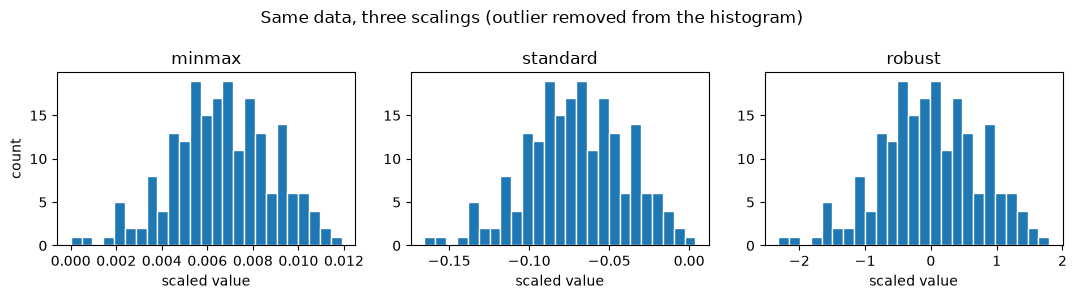

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, column in zip(axes, ["minmax", "standard", "robust"]):
    ax.hist(scaled.loc[1:, column], bins=25, edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel("scaled value")
axes[0].set_ylabel("count")
fig.suptitle("Same data, three scalings (outlier removed from the histogram)")
fig.tight_layout()
plt.show()

## 7. Exploratory pass

Shape, groups, relationship, and a look at the categorical column — the four questions of LP04-04.

In [10]:
print(clean_df.groupby("city")["satisfaction"].agg(["count", "mean", "median"]).round(2).to_string())
print("\npass rate (satisfaction >= 4):")
print((clean_df.assign(satisfied=clean_df["satisfaction"] >= 4)
       .groupby("city")["satisfied"].mean().round(3)).to_string())

           count  mean  median
city                          
Islamabad     25  2.76     3.0
Karachi       20  2.55     2.5
Lahore        15  2.80     3.0

pass rate (satisfaction >= 4):
city
Islamabad    0.28
Karachi      0.25
Lahore       0.40


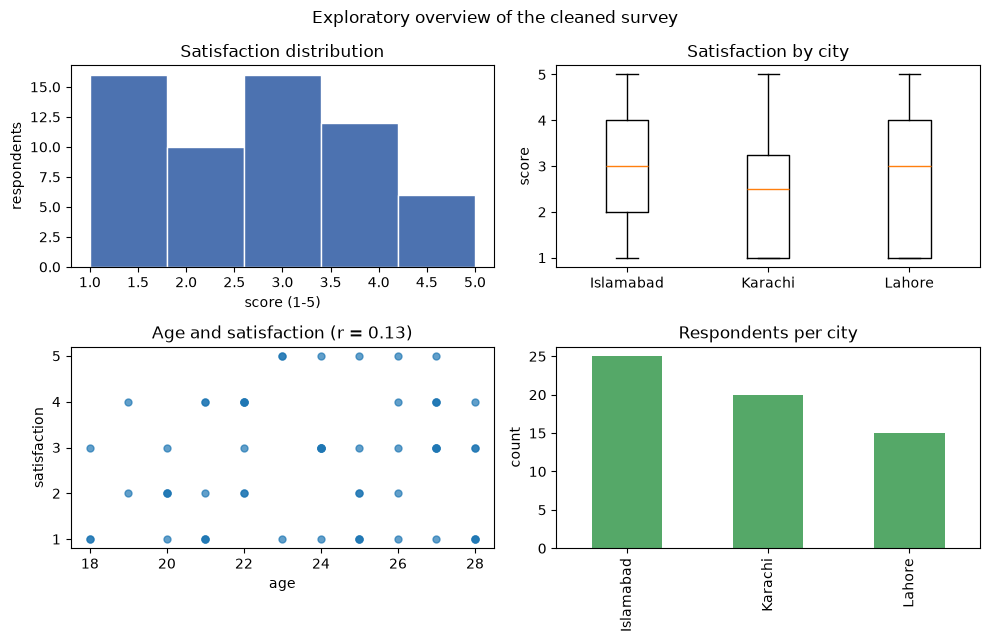

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))

axes[0, 0].hist(clean_df["satisfaction"], bins=5, edgecolor="white", color="#4c72b0")
axes[0, 0].set_title("Satisfaction distribution")
axes[0, 0].set_xlabel("score (1-5)")
axes[0, 0].set_ylabel("respondents")

cities = sorted(clean_df["city"].unique())
axes[0, 1].boxplot([clean_df.loc[clean_df["city"] == c, "satisfaction"] for c in cities])
axes[0, 1].set_xticks(range(1, len(cities) + 1), cities)
axes[0, 1].set_title("Satisfaction by city")
axes[0, 1].set_ylabel("score")

axes[1, 0].scatter(clean_df["age"], clean_df["satisfaction"], s=25, alpha=0.7)
axes[1, 0].set_title(f"Age and satisfaction (r = {clean_df['age'].corr(clean_df['satisfaction']):.2f})")
axes[1, 0].set_xlabel("age")
axes[1, 0].set_ylabel("satisfaction")

clean_df["city"].value_counts().plot(kind="bar", ax=axes[1, 1], color="#55a868")
axes[1, 1].set_title("Respondents per city")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("count")

fig.suptitle("Exploratory overview of the cleaned survey")
fig.tight_layout()
plt.show()

## 8. Exercises

1. Add a validation assertion that fails if any satisfaction value falls outside 1–5.
2. Recompute the city means using `score_missing` as a filter, and report how the imputed rows change
   each mean.
3. Detect outliers in `age` with the IQR fence *within each city* rather than globally. How many are
   flagged, and does the answer change?

In [12]:
# 1
valid = clean_df["satisfaction"].between(1, 5)
assert valid.all(), "satisfaction out of range"
print("validation passed for", len(clean_df), "rows")

validation passed for 60 rows


In [13]:
# 2
print(clean_df.groupby(["city", "score_missing"])["satisfaction"].mean().round(2).to_string())

city       score_missing
Islamabad  False            2.74
           True             3.00
Karachi    False            2.55
Lahore     False            2.77
           True             3.00


In [14]:
# 3
def fence_flags(frame, column):
    q1, q3 = frame[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    return (frame[column] < q1 - 1.5 * iqr) | (frame[column] > q3 + 1.5 * iqr)


flags = clean_df.groupby("city", group_keys=False).apply(lambda d: fence_flags(d, "age"))
print("flagged within city:", int(flags.sum()))

flagged within city: 0


## 9. Check yourself

1. Why must the imputation median be computed after deduplication, or the report adjusted if it is not?
2. Why does min-max scaling behave badly in the presence of one extreme value?
3. What does the `score_missing` indicator let a model do that a better imputation would not?

Next: take the [prerequisite diagnostic](../../diagnostic.md).